# 5. Ward, K-Means và cách kết hợp

Nếu thiếu tệp trung gian, chạy lần lượt notebook 04 đến phần ngay trước file này.

Muốn chạy toàn bộ trong một kernel: [mở notebook 00](00_Gamer_Behavior_Clustering.ipynb).

<details><summary>Danh sách tám phần</summary>

- [1. Tìm hiểu bài toán và dữ liệu](01_data_understanding.ipynb)

- [2. Thống kê và khám phá dữ liệu (EDA)](02_statistics_eda.ipynb)

- [3. Kiểm tra và làm sạch dữ liệu](03_data_cleaning.ipynb)

- [4. Chia dữ liệu và chuẩn hóa](04_data_transformation.ipynb)

- [5. Ward, K-Means và cách kết hợp](05_clustering.ipynb)

- [6. Đánh giá holdout và độ nhạy](06_model_evaluation.ipynb)

- [7. Hồ sơ người chơi và trực quan hóa](07_player_profiling.ipynb)

- [8. Gán người chơi và đề xuất chiến lược](08_prediction_strategy.ipynb)

</details>

## Khởi tạo và đọc dữ liệu

In [1]:
from pathlib import Path
import os, sys, json, hashlib
import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Markdown

# Tìm gốc dự án khi mở từ thư mục notebooks/, gamer_profiling/ hoặc workspace.
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / "gamer_profiling"]
ROOT = next((p for p in candidates if (p / "gamer_clustering.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục dự án gamer_profiling hoặc notebooks/.")
NBOUT = Path(os.environ.get("GAMER_NOTEBOOK_OUTPUT", str(ROOT / "outputs/notebook/latest")))
NBOUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(NBOUT / ".matplotlib"))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from gamer_clustering import clean_features, centers_from_labels, metrics, choose_k
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (pairwise_distances, silhouette_score, silhouette_samples,
                             davies_bouldin_score, adjusted_rand_score)
from sklearn.metrics.pairwise import pairwise_distances_argmin
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, cut_tree, dendrogram
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
import seaborn as sns

# Module .py dùng Agg khi chạy batch; trong notebook cần hiển thị hình ngay dưới ô code.
get_ipython().run_line_magic("matplotlib", "inline")
thread_limit = threadpool_limits(limits=2)
sns.set_theme(style="whitegrid", font="DejaVu Sans", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
SEED = 42
FEATURES = ["PlayTimeHours", "SessionsPerWeek", "AvgSessionDurationMinutes",
            "PlayerLevel", "AchievementsUnlocked"]
METHODS = ["KMeans", "Ward", "Ward_KMeans"]
SOURCE = ROOT / "data/online_gaming_behavior_dataset.csv"
df = pd.read_csv(SOURCE)
reference = json.loads((ROOT / "outputs/summary.json").read_text(encoding="utf-8"))

def require(name, previous):
    path = NBOUT / name
    if not path.is_file():
        raise FileNotFoundError(f"Chưa có {name}. Chạy notebook {previous} trước, hoặc Run All notebook 00.")
    return path

def save_plot(name):
    plt.tight_layout()
    plt.savefig(NBOUT / name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

Phần này cần chạy notebook 04 trước (hoặc dùng Run All của notebook 00).
Cả ba phương pháp so sánh trên cùng mẫu 4.000 người từ train và cùng các k = 2…8.

**K-Means:** giảm $J=\sum_r\sum_{x\in C_r}\|x-\mu_r\|^2$ bằng cách gán điểm và cập nhật tâm.
**Ward:** gộp hai cụm làm tăng tổng bình phương sai số ít nhất, xây cây rồi cắt ở k.
**Ward + K-Means:** lấy trung bình mỗi cụm Ward làm `init` cho K-Means. Khi đã khóa k,
K-Means mới tinh chỉnh trên toàn train (notebook 06). Ward dùng mẫu vì chi phí bộ nhớ tăng bậc hai.

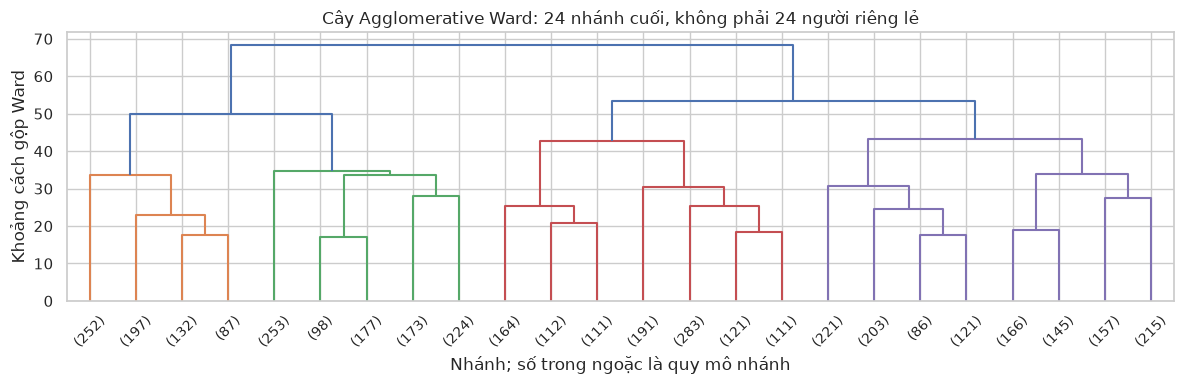

In [2]:
state = joblib.load(require("preprocessing.joblib", "04_data_transformation.ipynb"))
Z_train = state["Z_train"]
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(Z_train), min(4000, len(Z_train)), replace=False)
X_sample = Z_train[sample_idx]
eval_idx = rng.choice(len(X_sample), min(2000, len(X_sample)), replace=False)
distances = pairwise_distances(X_sample[eval_idx])
tree = linkage(X_sample, method="ward", metric="euclidean")
plt.figure(figsize=(12, 4))
dendrogram(tree, truncate_mode="lastp", p=24, show_leaf_counts=True)
plt.title("Cây Agglomerative Ward: 24 nhánh cuối, không phải 24 người riêng lẻ")
plt.xlabel("Nhánh; số trong ngoặc là quy mô nhánh"); plt.ylabel("Khoảng cách gộp Ward")
save_plot("05_dendrogram.png")

Ô dưới là phần kết hợp thực sự: `init=ward_centers`, `n_init=1`.
K-Means thuần dùng k-means++ với 20 khởi tạo. Trong bước chọn k, cả ba cùng học trên mẫu train.
Silhouette dùng một mẫu cố định 2.000 người; DBI dùng cả 4.000 người của mẫu train.

In [3]:
rows, sample_centers = [], {}
for k in range(2, 9):
    ward_labels = cut_tree(tree, n_clusters=k).ravel()
    ward_centers = centers_from_labels(X_sample, ward_labels)
    baseline = KMeans(n_clusters=k, init="k-means++", n_init=20,
                      max_iter=300, random_state=SEED).fit(X_sample)
    hybrid = KMeans(n_clusters=k, init=ward_centers, n_init=1,
                    max_iter=300, random_state=SEED).fit(X_sample)
    candidates = {"KMeans": (baseline.labels_, baseline.cluster_centers_),
                  "Ward": (ward_labels, ward_centers),
                  "Ward_KMeans": (hybrid.labels_, hybrid.cluster_centers_)}
    for name, (labels, centers) in candidates.items():
        sample_centers[(name, k)] = centers
        rows.append({"method": name, "k": k,
                     **metrics(X_sample, labels, eval_idx, distances)})
search = pd.DataFrame(rows)
display(search)

,method,k,silhouette,davies_bouldin,min_cluster_pct
0,KMeans,2,0.1477,2.3018,49.725
1,Ward,2,0.1155,2.6192,39.825
2,Ward_KMeans,2,0.1512,2.3196,50.000
3,KMeans,3,0.1360,1.9657,31.025
4,Ward,3,0.0909,2.4143,27.325
5,Ward_KMeans,3,0.1386,1.9821,31.800
6,KMeans,4,0.1469,1.8449,24.025
7,Ward,4,0.0857,2.2524,16.700
8,Ward_KMeans,4,0.1415,1.8612,24.550
9,KMeans,5,0.1497,1.6162,18.500


,method,k,silhouette,davies_bouldin,min_cluster_pct,rank_silhouette,rank_dbi,rank_sum
18,KMeans,8,0.1574,1.4336,11.275,1.0,1.0,2.0
12,KMeans,6,0.1547,1.4967,16.325,3.0,2.0,5.0
15,KMeans,7,0.1563,1.5236,12.150,2.0,3.0,5.0
9,KMeans,5,0.1497,1.6162,18.500,4.0,4.0,8.0
6,KMeans,4,0.1469,1.8449,24.025,6.0,5.0,11.0
0,KMeans,2,0.1477,2.3018,49.725,5.0,7.0,12.0
3,KMeans,3,0.1360,1.9657,31.025,7.0,6.0,13.0
13,Ward,6,0.0860,1.9838,9.675,3.0,3.0,6.0
1,Ward,2,0.1155,2.6192,39.825,1.0,7.0,8.0
4,Ward,3,0.0909,2.4143,27.325,2.0,6.0,8.0


,method,selected_k
0,KMeans,8
1,Ward,6
2,Ward_KMeans,8


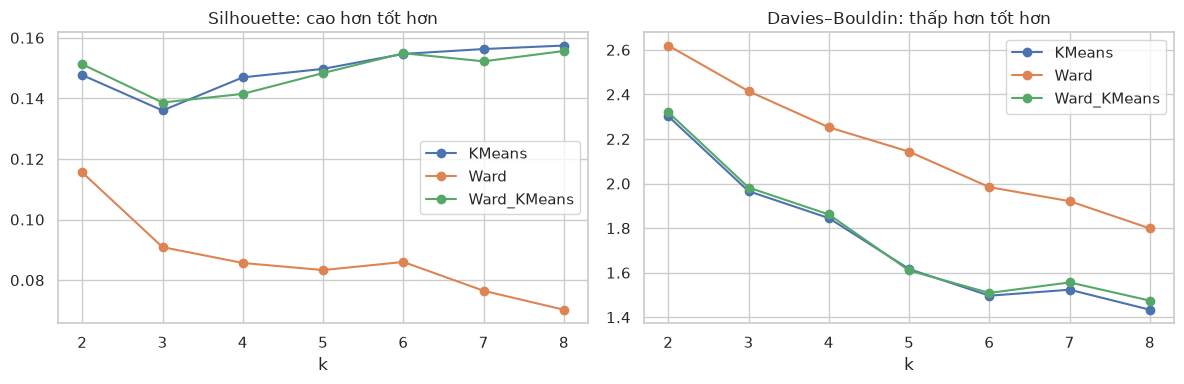

['C:\\Bop\\New folder\\gamer_profiling\\outputs\\notebook\\validation_bd40b6e5a2\\modular\\selection.joblib']

In [4]:
ranked = search.copy()
ranked["rank_silhouette"] = ranked.groupby("method").silhouette.rank(ascending=False, method="min")
ranked["rank_dbi"] = ranked.groupby("method").davies_bouldin.rank(method="min")
ranked["rank_sum"] = ranked.rank_silhouette + ranked.rank_dbi
selected = {name: choose_k(search[search.method == name]) for name in METHODS}
display(ranked.sort_values(["method", "rank_sum", "k"]))
display(pd.DataFrame({"method": list(selected), "selected_k": list(selected.values())}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, group in search.groupby("method"):
    axes[0].plot(group.k, group.silhouette, "o-", label=name)
    axes[1].plot(group.k, group.davies_bouldin, "o-", label=name)
axes[0].set_title("Silhouette: cao hơn tốt hơn")
axes[1].set_title("Davies–Bouldin: thấp hơn tốt hơn")
for ax in axes:
    ax.set_xlabel("k"); ax.legend()
save_plot("05_selection.png")
search.to_csv(NBOUT / "model_selection.csv", index=False)
joblib.dump({"selected": selected, "centers": sample_centers, "sample_idx": sample_idx,
             "eval_idx": eval_idx, "tree": tree, "search": search}, NBOUT / "selection.joblib")

Quy tắc chọn: tổng hạng Silhouette giảm và DBI tăng nhỏ nhất; hòa thì ưu tiên Silhouette, rồi k nhỏ.
**k = 8 ở biên trên dải đã thử**: đây là lựa chọn trong dải 2–8, chưa chứng minh tám nhóm tự nhiên.
Phương pháp kết hợp là sản phẩm chính theo đề, được xác định trước khi xem holdout.